# 第 47 课｜技术指标公式与可执行时点

本 Notebook 对应「365 天量化金融」第 47 课。课程方法来自本地完整视频、课件截图和本地 Whisper 口播整理；这里把它重建为默认离线、可核对、可重复执行的量化教学实现。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/47_youtube-M46pgFS52KI/index.html`
- 环境：`pkm-quant`
- 数据：离线模拟 OHLCV；指标由 pandas 手工实现
- 状态：可运行学习稿；不代表策略收益承诺

> 网络接口和研究计算分离：Notebook 默认不请求第三方服务。真实接口只作为适配层示意，计算使用带来源声明的本地快照，避免限流、字段变化和历史数据重算破坏复现。

## 本节量化问题

MA、RSI、MACD、ATR 都是历史价格的确定性变换。重点不是记住默认参数，而是明确公式、窗口、NaN 与信号何时可成交。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 1. 用可手算序列核对 MA 和 RSI

- `SMA_n`：最近 n 个收盘价的算术平均；
- `RSI_n = 100 - 100/(1+RS)`；
- `RS = 平均上涨幅度 / 平均下跌幅度`。

`min_periods=n` 表示窗口未满时保留 NaN，不用短样本冒充完整指标。

In [2]:
# 先用 6 个价格展示 3 日均线和 RSI 的中间量。
small = pd.Series([100, 102, 101, 104, 106, 103], name="close", dtype=float)
delta = small.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
sma3 = small.rolling(3, min_periods=3).mean()
avg_gain = gain.rolling(3, min_periods=3).mean()
avg_loss = loss.rolling(3, min_periods=3).mean()
rsi3 = 100 - 100 / (1 + avg_gain / avg_loss)

check = pd.DataFrame({"close": small, "delta": delta, "gain": gain, "loss": loss, "SMA3": sma3, "RSI3": rsi3})
display(check)
assert sma3.iloc[2] == (100 + 102 + 101) / 3

,close,delta,gain,loss,SMA3,RSI3
0,100.0,NaN,NaN,NaN,NaN,NaN
1,102.0,2.0,2.0,-0.0,NaN,NaN
2,101.0,-1.0,0.0,1.0,101.000000,NaN
3,104.0,3.0,3.0,-0.0,102.333333,83.333333
4,106.0,2.0,2.0,-0.0,103.666667,83.333333
5,103.0,-3.0,0.0,3.0,104.333333,62.500000


## 2. 在完整 OHLCV 上实现 MA、RSI、MACD 与 ATR

`ewm(span, adjust=False)` 计算递归 EMA。ATR 的 True Range 同时考虑日内高低与隔夜跳空，量纲是价格金额，不是方向。

In [3]:
# 构造完整指标表，并保留窗口未满产生的 NaN。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
bars = daily.query("symbol == 'EV_A'").sort_values("date").set_index("date").copy()
close = bars["close"]
delta = close.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

bars["MA20"] = close.rolling(20, min_periods=20).mean()
bars["MA60"] = close.rolling(60, min_periods=60).mean()
avg_gain = gain.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
avg_loss = loss.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
bars["RSI14"] = 100 - 100 / (1 + avg_gain / avg_loss)
ema12 = close.ewm(span=12, adjust=False, min_periods=12).mean()
ema26 = close.ewm(span=26, adjust=False, min_periods=26).mean()
bars["DIF"] = ema12 - ema26
bars["DEA"] = bars["DIF"].ewm(span=9, adjust=False, min_periods=9).mean()
bars["MACD_hist"] = bars["DIF"] - bars["DEA"]
previous_close = close.shift(1)
true_range = pd.concat([
    bars["high"] - bars["low"],
    (bars["high"] - previous_close).abs(),
    (bars["low"] - previous_close).abs(),
], axis=1).max(axis=1)
bars["ATR14"] = true_range.ewm(alpha=1/14, adjust=False, min_periods=14).mean()

display(bars[["close", "MA20", "RSI14", "DIF", "DEA", "MACD_hist", "ATR14"]].tail())
assert bars["MA20"].iloc[:19].isna().all()
assert bars["ATR14"].dropna().gt(0).all()

,close,MA20,RSI14,DIF,DEA,MACD_hist,ATR14
date,,,,,,,
2025-11-19,43.3078,42.426095,54.511694,0.196486,-0.041762,0.238248,0.902239
2025-11-20,42.9623,42.554095,51.221409,0.177854,0.002162,0.175693,0.923215
2025-11-21,42.0288,42.536300,43.569385,0.086762,0.019082,0.067681,0.962657
2025-11-24,41.6918,42.509645,41.177788,-0.012478,0.012770,-0.025248,0.954189
2025-11-25,40.4624,42.472355,33.872991,-0.188159,-0.027416,-0.160743,1.003261


## 3. 当日收盘形成的信号要到下一期执行

`raw_signal_t` 使用 t 日收盘后才能确定。策略收益写为

`strategy_return_t = position_{t-1} × asset_return_t - cost_t`。

因此 `position = raw_signal.shift(1)`；不做这一步会假设能够以已经知道的收盘价成交。

In [4]:
# 比较错误的同收盘成交与向后移动一日的可执行信号。
features = bars.dropna(subset=["MA20", "MA60"]).copy()
features["asset_return"] = features["close"].pct_change(fill_method=None)
features["raw_signal"] = (features["MA20"] > features["MA60"]).astype(int)
features["position"] = features["raw_signal"].shift(1).fillna(0)
features["turnover"] = features["position"].diff().abs().fillna(features["position"].abs())
features["strategy_return"] = (
    features["position"] * features["asset_return"] - 0.001 * features["turnover"]
)
features["wrong_same_close_return"] = features["raw_signal"] * features["asset_return"]

display(features[["close", "MA20", "MA60", "raw_signal", "position", "strategy_return"]].head())
assert features["position"].iloc[1] == features["raw_signal"].iloc[0]

,close,MA20,MA60,raw_signal,position,strategy_return
date,,,,,,
2023-03-27,29.1953,30.125250,28.865173,1,0.0,NaN
2023-03-28,29.1197,30.116180,28.891210,1,1.0,-0.003589
2023-03-29,28.6392,30.081045,28.909882,1,1.0,-0.016501
2023-03-30,29.0353,30.108640,28.930193,1,1.0,0.013831
2023-03-31,29.3786,30.102255,28.940710,1,1.0,0.011824


## 4. 图表区分指标发现日与持有收益

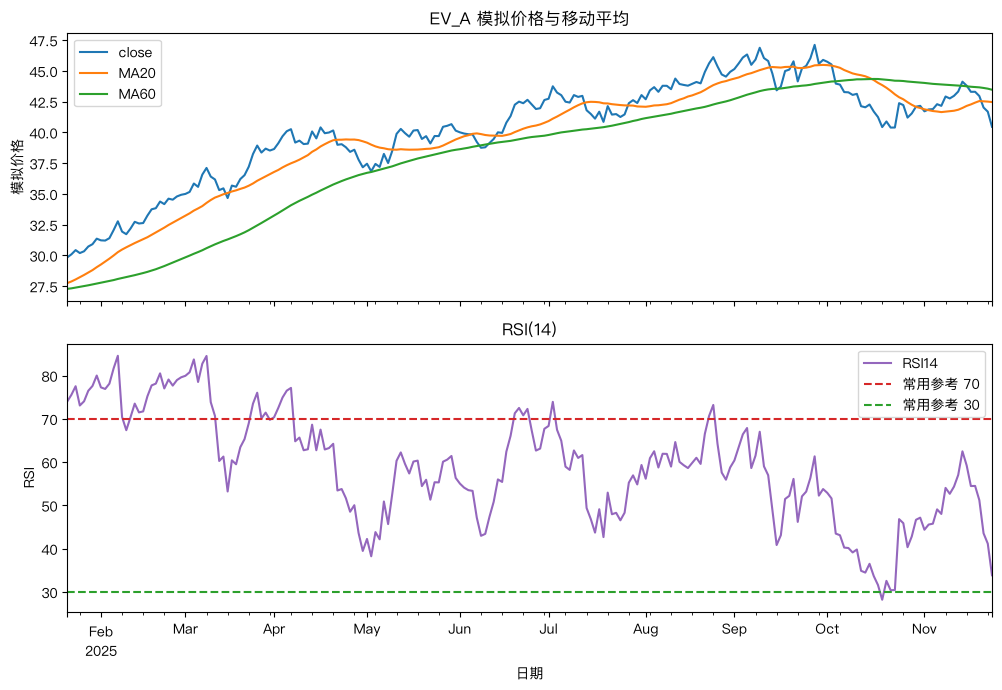

In [5]:
# 绘制价格均线和 RSI；图表只做诊断，不把阈值当作投资建议。
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
bars[["close", "MA20", "MA60"]].tail(220).plot(ax=axes[0], title="EV_A 模拟价格与移动平均")
bars["RSI14"].tail(220).plot(ax=axes[1], title="RSI(14)", color="tab:purple")
axes[1].axhline(70, color="tab:red", linestyle="--", label="常用参考 70")
axes[1].axhline(30, color="tab:green", linestyle="--", label="常用参考 30")
axes[0].set_ylabel("模拟价格")
axes[1].set_ylabel("RSI")
axes[1].set_xlabel("日期")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "47_indicators.png", dpi=150)
plt.show()

## 方法边界与复用结论


- RSI 70/30 是常用参数，不是上涨或下跌概率。
- 多个价格指标可能高度相关，“共振”不等于独立证据。
- 指标公式正确不代表策略可实现；成交时点、成本和参数稳定性仍需样本外检验。


本课代码验证的是方法和数据契约，不是未来收益。迁移到真实研究前，还需重新核对来源授权、复权、时区、可得时间、交易成本和样本外边界。